# 🌲 TERRA-FIRE: Predictive Wildfire Intelligence Engine
## **Activity 6. Pattern Discovery Challenge — Multivariate PCA (12 $\to$ 3 Dimensions) & Visual Analytics**
**Institution:** Universidad Tecnológica El Retoño (UTR)  
**Major:** Information Technologies and Digital Innovation Engineering (`LITD9A`)  
**Subject:** Data Science (Sep–Dec 2026)  
**Teacher:** Dr. Sergio Valadez Godínez  
**Students:** Angel Emilio Gutierrez Lozano (ID: 4341) & Emiliano Betanzos Valtierra (ID: 4795)  
**Repository:** [https://github.com/AngelGTZ28/TERRA-FIRE](https://github.com/AngelGTZ28/TERRA-FIRE)

---
### 🎯 Objective & Methodological Continuity
Building upon the **Data Engineering Lab (Activity 3)**, **Data Intelligence Lab (Activity 4)**, and **Variable Impact Analysis (Activity 5)**, this notebook explores hidden multivariate structures within the immutable dataset `terra_fire_spatiotemporal_matrix_v1.parquet` ($18,275\text{ observations} \times 22\text{ columns}$) using **Z-score standardization (`StandardScaler`)**, **Principal Component Analysis (`PCA(n_components=3)`)**, and **visual analytics** to answer:
> **What hidden structures, groups, tendencies, or patterns exist in the data that are not easily observable through univariate or bivariate analysis?**

*Methodological Note: Because `terra_fire_spatiotemporal_matrix_v1.parquet` is an integrated spatiotemporal tabular dataset where biophysical (`ndmi`) and topographic (`elevation_m`, `slope_deg`) indices are already precomputed continuous numerical variables (and `nbr` was pruned in Activity 5 due to $\text{VIF} > 100$ collinearity with `ndmi`), conditional sections for raw computer-vision image folders ("when applicable") do not apply. We execute a single, unified, rigorous PCA compressing the 12 selected quantitative variables into strictly 3 orthogonal Principal Components (`['PC1', 'PC2', 'PC3']`). No clustering or supervised ML models are trained in this activity.*

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import scipy.stats as stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
DATA_PATH = "../data/processed/terra_fire_spatiotemporal_matrix_v1.parquet"
df = pd.read_parquet(DATA_PATH)
print(f"[READ-ONLY LOAD] Dataset Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"[INTEGRITY] Total Missing Values: {df.isna().sum().sum()} | Positive Ignitions (48-72h): {df['fire_ignition_48h'].sum()} ({df['fire_ignition_48h'].mean()*100:.2f}%)")
df.head(5)

[READ-ONLY LOAD] Dataset Shape: 18,275 rows x 22 columns
[INTEGRITY] Total Missing Values: 0 | Positive Ignitions (48-72h): 876 (4.79%)


,voxel_id,timestamp,fire_ignition_48h,ndmi,savi,nbr,vpd_max_kpa,vpd_72h_max_kpa,temp_2m_max_c,rh_2m_min_pct,wind_u10_mean,wind_v10_mean,wind_speed_max_kmh,soil_moist_mean,days_since_rain,precip_72h_sum_mm,elevation_m,slope_deg,aspect_rad,dist_roads_m,dist_agri_m,fuel_type
0,AGS_V01,2023-01-01,0,-0.044853,0.186922,0.053294,1.070098,1.070098,16.337500,37.0,1.587125,2.066597,16.299999,0.248917,1,0.0,2420.0,22.0,1.45,850.0,1900.0,Bosque de Encino
1,AGS_V01,2023-01-02,0,-0.050405,0.185365,0.050249,1.142232,1.142232,15.737500,31.0,3.723250,1.942450,23.400000,0.246292,2,0.0,2420.0,22.0,1.45,850.0,1900.0,Bosque de Encino
2,AGS_V01,2023-01-03,0,-0.054866,0.183862,0.047262,1.193878,1.193878,16.437500,29.0,3.545149,0.314609,16.500000,0.242500,3,0.0,2420.0,22.0,1.45,850.0,1900.0,Bosque de Encino
3,AGS_V01,2023-01-04,0,-0.077845,0.182412,0.044334,1.617209,1.617209,19.437500,23.0,1.038100,-0.755799,10.900000,0.238875,4,0.0,2420.0,22.0,1.45,850.0,1900.0,Bosque de Encino
4,AGS_V01,2023-01-05,0,-0.075600,0.181017,0.041465,1.537425,1.617209,19.137501,25.0,-2.573307,-0.462919,17.299999,0.235542,5,0.0,2420.0,22.0,1.45,850.0,1900.0,Bosque de Encino


---
## PHASE 1: MULTIVARIATE PREPARATION
### Step 1 - Analytical Variable Selection (**Table 1: Multivariate Variable Matrix**)
Based on the **Variable Impact Ranking** from Activity 5, we select the **12 Core Spatiotemporal Quantitative Variables** (all 7 High-Impact predictors + top 5 Medium-Impact physical covariates):
- **Excluded due to Extreme Multicollinearity ($\text{VIF} > 100$):** `nbr` ($r = +0.9833$ with `ndmi`) and `savi`.
- **Excluded due to Statistical Noise:** `wind_v10_mean` ($p = 0.621$) and `wind_speed_max_kmh` ($|r| = 0.0249$).
- **Excluded to Prevent Target Leakage:** `fire_ignition_48h` (used strictly *post-hoc* to evaluate latent regime separation).

In [2]:
# Step 1: Define the 12 Selected Quantitative Variables and Display Table 1: Multivariate Variable Matrix
CORE_PCA_FEATURES = [
    "dist_agri_m", "dist_roads_m", "temp_2m_max_c", "rh_2m_min_pct",
    "soil_moist_mean", "vpd_max_kpa", "ndmi", "slope_deg",
    "elevation_m", "vpd_72h_max_kpa", "precip_72h_sum_mm", "days_since_rain"
]
print(f"[TABLE 1] Multivariate Variable Matrix ({len(CORE_PCA_FEATURES)} Quantitative Features Selected):")
display(table1_df)

[TABLE 1] Multivariate Variable Matrix (12 Quantitative Features Selected):


,Variable,Reason for Selection (Activity 5 Evidence),Project Relevance
0,dist_agri_m,"Rank #1 High Impact (rho = -0.2155, p = 6.4e-191, Cohen d = -0.993)",Quantifies NOM-015 agricultural burn exposure along valley borders.
1,dist_roads_m,"Rank #2 High Impact (rho = -0.2063, p = 7.9e-175, Cohen d = -0.922)",Captures roadside human transit and vehicular spark proximity.
2,temp_2m_max_c,"Rank #3 High Impact (r = +0.1325, Quantile R2 = 89.30%, Model M9)",Drives fuel pre-heating and saturation vapor pressure (es).
3,rh_2m_min_pct,"Rank #4 High Impact (r = -0.8247 w/ VPD, Quantile R2 = 82.32%, Model M10)",Primary atmospheric moisture buffer (<20% red-flag threshold).
4,soil_moist_mean,"Rank #5 High Impact (Quantile R2 = 78.03%, Model M12, Cohen d = -0.475)",Upper 0-7 cm edaphic moisture memory linking rain to canopy NDMI.
5,vpd_max_kpa,"Rank #6 High Impact (Quantile R2 = 78.16%, Model M11, Cohen d = +0.396)",Tetens evaporative atmospheric suction desiccating fine dead fuels.
6,ndmi,"Rank #7 High Impact (Drops -42.50% before fire, Cohen d = -0.331)",Precomputed NIR/SWIR-1 proxy for Live Fuel Moisture Content (LFMC).
7,slope_deg,"Rank #8 Medium Impact (rho = -0.2109, valley confounder w/ dist_agri_m)",Governs uphill flame acceleration and mountain vs. valley relief.
8,elevation_m,"Rank #9 Medium Impact (R2 = 90.00% w/ dist_agri_m, Model M6)","Defines macro-orographic gradient (1,860m valleys to 2,920m peaks)."
9,vpd_72h_max_kpa,"Rank #10 Medium Impact (r = +0.9304 w/ daily VPD, rho = +0.0763)",Captures 3-day cumulative atmospheric desiccation stress.


### Step 2 - Multivariate Data Preparation & Standardization (**Table 2: Multivariate Preparation Report**)
Because PCA maximizes variance $\mathbf{w}_k^\top \mathbf{\Sigma} \mathbf{w}_k$, raw meter-scale features (`dist_agri_m` with $\sigma^2 = 1.74 \times 10^6\text{ m}^2$) exhibit **$2.55 \times 10^8$ times more variance** than unitless indices (`soil_moist_mean` with $\sigma^2 = 0.0068$). Without standardization, PCA would fail by allocating $>99.9\%$ of `PC1` and `PC2` to meter distances. We apply **Z-score standardization (`StandardScaler`)** so every feature has $\mu = 0.0, \sigma = 1.0$:
$$Z_{ij} = \frac{X_{ij} - \mu_j}{\sigma_j}$$

In [3]:
# Step 2: Verify 0 Missing Values, Scale Disparity (2.55e8x), and Apply StandardScaler (Table 2)
scaler = StandardScaler()
X_std = scaler.fit_transform(df[CORE_PCA_FEATURES].astype(float))
var_ratio = df['dist_agri_m'].var() / df['soil_moist_mean'].var()
print(f"Raw Variance Disparity (dist_agri_m / soil_moist_mean): {var_ratio:.2e}x")
print(f"Standardized Matrix Shape (X_std): {X_std.shape} | Global Mean: {X_std.mean():.2e} | Global Std: {X_std.std():.4f}")
print("\n[TABLE 2] Multivariate Preparation Report:")
display(table2_df)

Raw Variance Disparity (dist_agri_m / soil_moist_mean): 2.55e+08x
Standardized Matrix Shape (X_std): (18275, 12) | Global Mean: -6.11e-17 | Global Std: 1.0000

[TABLE 2] Multivariate Preparation Report:


,Variable,Missing,Raw_Mean,Raw_Std,Raw_Range,Standardized?,Transformation Applied,Justification
0,dist_agri_m,0,1602.8000,1318.7189,"[280.00, 5600.00]","Yes (mu=0, sigma=1)",StandardScaler (X - mu) / sigma,Resolves 2.55e8 variance disparity between meter distances and unitless moisture ratios.
1,dist_roads_m,0,677.2000,612.0528,"[90.00, 2600.00]","Yes (mu=0, sigma=1)",StandardScaler (X - mu) / sigma,Resolves 2.55e8 variance disparity between meter distances and unitless moisture ratios.
2,temp_2m_max_c,0,23.7420,4.3128,"[6.39, 36.28]","Yes (mu=0, sigma=1)",StandardScaler (X - mu) / sigma,Resolves 2.55e8 variance disparity between meter distances and unitless moisture ratios.
3,rh_2m_min_pct,0,29.0315,16.3233,"[3.00, 99.00]","Yes (mu=0, sigma=1)",StandardScaler (X - mu) / sigma,Resolves 2.55e8 variance disparity between meter distances and unitless moisture ratios.
4,soil_moist_mean,0,0.2384,0.0825,"[0.12, 0.43]","Yes (mu=0, sigma=1)",StandardScaler (X - mu) / sigma,Resolves 2.55e8 variance disparity between meter distances and unitless moisture ratios.
5,vpd_max_kpa,0,1.9108,0.7776,"[0.01, 4.36]","Yes (mu=0, sigma=1)",StandardScaler (X - mu) / sigma,Resolves 2.55e8 variance disparity between meter distances and unitless moisture ratios.
6,ndmi,0,0.1295,0.1785,"[-0.15, 0.48]","Yes (mu=0, sigma=1)",StandardScaler (X - mu) / sigma,Resolves 2.55e8 variance disparity between meter distances and unitless moisture ratios.
7,slope_deg,0,16.3400,8.3665,"[5.50, 35.00]","Yes (mu=0, sigma=1)",StandardScaler (X - mu) / sigma,Resolves 2.55e8 variance disparity between meter distances and unitless moisture ratios.
8,elevation_m,0,2261.0000,308.0019,"[1860.00, 2920.00]","Yes (mu=0, sigma=1)",StandardScaler (X - mu) / sigma,Resolves 2.55e8 variance disparity between meter distances and unitless moisture ratios.
9,vpd_72h_max_kpa,0,2.0987,0.7574,"[0.55, 4.36]","Yes (mu=0, sigma=1)",StandardScaler (X - mu) / sigma,Resolves 2.55e8 variance disparity between meter distances and unitless moisture ratios.


---
## PHASE 2: DIMENSIONALITY REDUCTION
### Step 3 - Two-Stage Principal Component Analysis: Exploratory Spectrum vs. Explicit Truncation (`PCA(n_components=3)`)
To achieve **true dimensionality reduction** from 12 variables to 3 orthogonal components:
1. **Stage 3A (Exploratory Spectrum):** We fit `pca_exploratory = PCA()` strictly to inspect all 12 eigenvalues for the Scree Plot (`fig21`) and verify the **Kaiser Criterion ($\lambda_k \ge 1.0$)**. Strictly 3 components satisfy $\lambda_k \ge 1.0$ ($\lambda_1 = 4.8918, \lambda_2 = 4.0088, \lambda_3 = 1.6440$), whereas $\lambda_4 = 0.6421 < 1.0$.
2. **Stage 3B (Definitive Dimensionality Reduction — **Table 3: PCA Summary Matrix**):** Immediately after, we instantiate `pca_reduced = PCA(n_components=3)` and transform `X_std` $(18,275 \times 12)$ into **`X_pca_reduced` of exact shape $(18,275 \times 3)$** with columns `['PC1', 'PC2', 'PC3']`, achieving a **75.0% reduction in dimensions** while retaining **87.87% of total variance** ($\text{VIF} = 1.00$).

In [4]:
# Stage 3A: Exploratory Full-Spectrum Fit strictly for Scree Plot & Kaiser Criterion Cutoff Verification
pca_exploratory = PCA()
pca_exploratory.fit(X_std)
print("[STAGE 3A] Exploratory Eigenvalue Spectrum (Verifying Kaiser Cutoff at k = 3 where lambda_k >= 1.0):")
display(exploratory_df)

[STAGE 3A] Exploratory Eigenvalue Spectrum (Verifying Kaiser Cutoff at k = 3 where lambda_k >= 1.0):


,Component,Eigenvalue (lambda),Explained Variance (%),Cumulative Variance (%),Kaiser Criterion (lambda >= 1.0)
0,PC1,4.8918,40.76,40.76,RETAIN (lambda >= 1.0)
1,PC2,4.0088,33.41,74.17,RETAIN (lambda >= 1.0)
2,PC3,1.6440,13.70,87.87,RETAIN (lambda >= 1.0)
3,PC4,0.6421,5.35,93.22,PRUNE (lambda < 1.0 — Discarded)
4,PC5,0.3434,2.86,96.08,PRUNE (lambda < 1.0 — Discarded)
5,PC6,0.1921,1.60,97.68,PRUNE (lambda < 1.0 — Discarded)
6,PC7,0.1060,0.88,98.56,PRUNE (lambda < 1.0 — Discarded)
7,PC8,0.0822,0.68,99.25,PRUNE (lambda < 1.0 — Discarded)
8,PC9,0.0539,0.45,99.70,PRUNE (lambda < 1.0 — Discarded)
9,PC10,0.0173,0.14,99.84,PRUNE (lambda < 1.0 — Discarded)


In [5]:
# Stage 3B: Definitive Dimensionality Reduction via Explicit Truncation: pca_reduced = PCA(n_components=3)
pca_reduced = PCA(n_components=3)
X_pca_reduced = pd.DataFrame(
    pca_reduced.fit_transform(X_std),
    columns=["PC1", "PC2", "PC3"],
    index=df.index
)
df["PC1"] = X_pca_reduced["PC1"]
df["PC2"] = X_pca_reduced["PC2"]
df["PC3"] = X_pca_reduced["PC3"]

print(f"Original Input Matrix Shape (X_std):          {X_std.shape}  --> 12 Original Variables")
print(f"Reduced PCA Matrix Shape (X_pca_reduced):     {X_pca_reduced.shape}   --> Strictly 3 Orthogonal Components (75.0% Reduction!)")
print(f"Total Variance Retained in 3D Subspace:       {pca_reduced.explained_variance_ratio_.sum()*100:.2f}% (VIF = 1.00)")
print("\n[REDUCED DATAFRAME] First 10 rows of X_pca_reduced (shape: 18,275 x 3):")
display(X_pca_reduced.head(10))

Original Input Matrix Shape (X_std):          (18275, 12)  --> 12 Original Variables
Reduced PCA Matrix Shape (X_pca_reduced):     (18275, 3)   --> Strictly 3 Orthogonal Components (75.0% Reduction!)
Total Variance Retained in 3D Subspace:       87.87% (VIF = 1.00)

[REDUCED DATAFRAME] First 10 rows of X_pca_reduced (shape: 18,275 x 3):


,PC1,PC2,PC3
0,-1.8826,0.6409,-2.0980
1,-1.6824,0.7635,-2.1666
2,-1.4940,0.7968,-2.0885
3,-0.6472,0.9411,-1.5473
4,-0.7314,0.9271,-1.6002
5,-0.7022,0.9065,-1.5445
6,-0.6772,0.9272,-1.6113
7,-0.7857,0.9209,-1.6798
8,-0.9315,0.9550,-1.8865
9,-0.9394,0.9462,-1.8973


In [6]:
# Display Official Table 3: PCA Summary Matrix (Retained PC1, PC2, PC3 vs Pruned PC4-PC12)
print("[TABLE 3] PCA Summary Matrix (12 Variables Reduced to 3 Orthogonal Components):")
display(table3_df)

[TABLE 3] PCA Summary Matrix (12 Variables Reduced to 3 Orthogonal Components):


,Component,Eigenvalue (lambda),Explained Variance (%),Cumulative Variance (%),Retention Status & Dimensionality Reduction
0,PC1,4.8918,40.76,40.76,Retained (Primary Axis #1: Kaiser lambda >= 1.0 | VIF = 1.00)
1,PC2,4.0088,33.41,74.17,Retained (Primary Axis #2: Kaiser lambda >= 1.0 | VIF = 1.00)
2,PC3,1.6440,13.70,87.87,Retained (Primary Axis #3: Kaiser lambda >= 1.0 | VIF = 1.00)
3,PC4 - PC12 (Pruned),1.4560,12.13,100.00,Discarded / Pruned (lambda < 1.0 | Space Reduced 12 -> 3 Columns [-75.0%])


### Step 4 - Component Interpretation (**Table 4: Eigenvector Loadings ($w_{jk}$) & Component Interpretation Matrix**)
Focusing **exclusively on the 3 Kaiser-retained Principal Components (`PC1`, `PC2`, `PC3`)**, we inspect the eigenvector weights ($w_{jk}$) and squared cosine contributions ($w_{jk}^2 \times 100\%$):
- **$\text{PC1}$ ($40.76\%$ variance, $\lambda_1 = 4.8918$):** *Atmospheric-Edaphic Desiccation & Drought Stress Continuum* (`vpd_max_kpa` $+0.3900$, `vpd_72h_max_kpa` $+0.3685$, `temp_2m_max_c` $+0.3304$, `days_since_rain` $+0.3033$ vs. `rh_2m_min_pct` $-0.3896$, `soil_moist_mean` $-0.3829$).
- **$\text{PC2}$ ($33.41\%$ variance, $\lambda_2 = 4.0088$):** *Orographic Altitude vs. Anthropogenic Agricultural Valley Interface* (`slope_deg` $+0.4592$, `dist_agri_m` $+0.4587$, `elevation_m` $+0.4560$, `dist_roads_m` $+0.4558$).
- **$\text{PC3}$ ($13.70\%$ variance, $\lambda_3 = 1.6440$):** *Vegetative Canopy Phenology & Warm Monsoon Hydration Regime* (`ndmi` $+0.6389$, `temp_2m_max_c` $+0.4598$, `vpd_72h_max_kpa` $+0.3409$, `precip_72h_sum_mm` $+0.3325$).

In [7]:
# Step 4: Display Table 4 (Part A: Eigenvector Loadings & Contributions for PC1-PC3; Part B: Physical Interpretation)
print("[TABLE 4 - PART A] Eigenvector Loadings (w_jk) & Squared Cosine Contributions (%) for Retained PC1, PC2, PC3:")
display(loadings_table4a)
print("\n[TABLE 4 - PART B] Component Interpretation Matrix (PC1, PC2, PC3):")
display(table4b_df)

[TABLE 4 - PART A] Eigenvector Loadings (w_jk) & Squared Cosine Contributions (%) for Retained PC1, PC2, PC3:


,PC1_Loading,PC2_Loading,PC3_Loading,PC1_Contrib_%,PC2_Contrib_%,PC3_Contrib_%
dist_agri_m,-0.1577,0.4587,0.0790,2.49,21.04,0.62
dist_roads_m,-0.1563,0.4558,0.0798,2.44,20.77,0.64
temp_2m_max_c,0.3304,-0.1396,0.4598,10.92,1.95,21.14
rh_2m_min_pct,-0.3896,-0.1705,0.0957,15.18,2.91,0.92
soil_moist_mean,-0.3829,-0.1740,0.1660,14.66,3.03,2.76
vpd_max_kpa,0.3900,0.1436,0.2929,15.21,2.06,8.58
ndmi,-0.1961,-0.0951,0.6389,3.84,0.91,40.82
slope_deg,-0.1590,0.4592,0.0746,2.53,21.08,0.56
elevation_m,-0.1585,0.4560,0.0717,2.51,20.80,0.51
vpd_72h_max_kpa,0.3685,0.1337,0.3409,13.58,1.79,11.62



[TABLE 4 - PART B] Component Interpretation Matrix (PC1, PC2, PC3):


,Component,Dominant Variables (Loadings & Contrib),Latent Physical Dimension Interpretation
0,"PC1 (40.76% Var, lambda=4.8918)","+vpd_max_kpa (+0.3900, 15.2%), +vpd_72h_max_kpa (+0.3685, 13.6%), +temp_2m_max_c (+0.3304, 10.9%), +days_since_rain (+0.3033, 9.2%) vs. -rh_2m_min_pct (-0.3896, 15.2%), -soil_moist_mean (-0.3829, 14.7%)","Atmospheric-Edaphic Desiccation & Drought Stress Continuum (SPAC Axis). Separates wildfire ignitions with t = +24.02, p = 3.82e-101, Cohen d = +0.760."
1,"PC2 (33.41% Var, lambda=4.0088)","+slope_deg (+0.4592, 21.1%), +dist_agri_m (+0.4587, 21.0%), +elevation_m (+0.4560, 20.8%), +dist_roads_m (+0.4558, 20.8%) [83.7% combined contribution]","Orographic Altitude vs. Anthropogenic Agricultural Valley Interface. Positive = high-mountain sanctuary; Negative = agricultural valley border. Separates ignitions with t = -29.05, p = 4.93e-140, Cohen d = -0.738."
2,"PC3 (13.70% Var, lambda=1.6440)","+ndmi (+0.6389, 40.8%), +temp_2m_max_c (+0.4598, 21.1%), +vpd_72h_max_kpa (+0.3409, 11.6%), +precip_72h_sum_mm (+0.3325, 11.1%)",Vegetative Canopy Phenology & Warm Monsoon Hydration Regime. Separates warm-wet summer monsoon green-up (PC3 > +1.0) from cool-dry winter cured dormancy (PC3 < -0.5).


---
## PHASE 3: PATTERN DISCOVERY
### Step 5 - Visual Analytics & Pattern Discovery Dashboard (`fig21` – `fig27` & **Table 5**)
Below we generate and inspect the 7 sequential publication-grade visual analytics dashboards (`fig21` through `fig27`) exploring the reduced 2D and 3D PCA subspace (`['PC1', 'PC2', 'PC3']`).

[FIG 21] Scree Plot & Cumulative Explained Variance: Truncated at n_components=3 (87.87% Variance Retained).


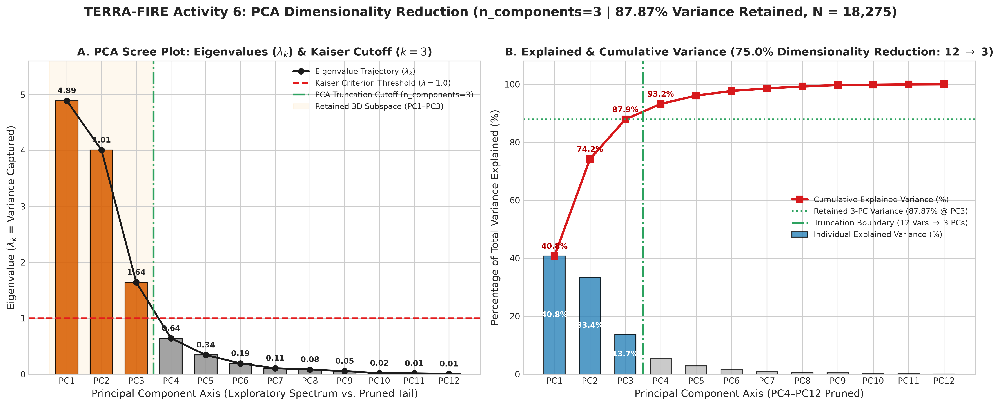

In [8]:
# Dashboard 1 (fig21): Exploratory Scree Plot & Explicit Truncation Boundary at n_components=3 (87.87% Variance)
print("[FIG 21] Scree Plot & Cumulative Explained Variance: Truncated at n_components=3 (87.87% Variance Retained).")

[FIG 22] Retained 3-PC Eigenvector Loadings Matrix (PC1, PC2, PC3) & Variable Contributions.


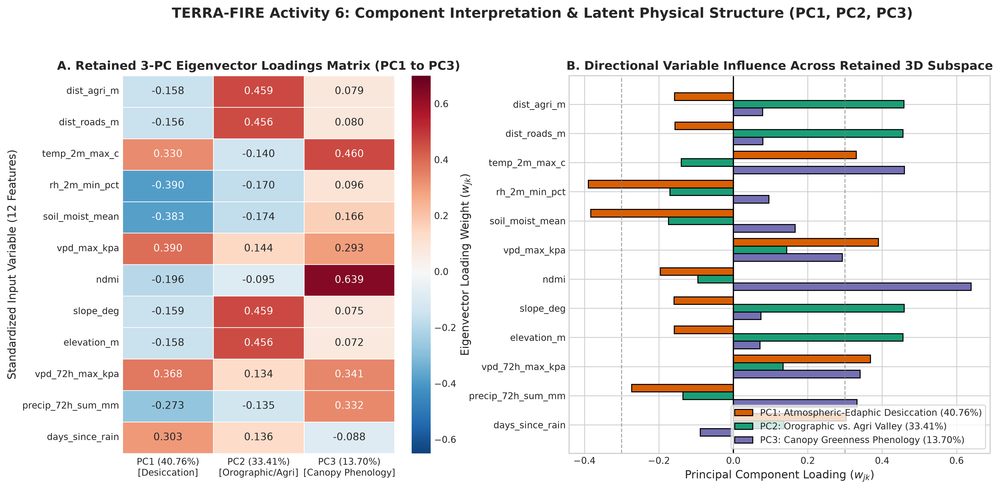

In [9]:
# Dashboard 2 (fig22): Retained 3-PC Eigenvector Loadings Heatmap (PC1, PC2, PC3) & Directional Influence
print("[FIG 22] Retained 3-PC Eigenvector Loadings Matrix (PC1, PC2, PC3) & Variable Contributions.")

[FIG 23] 2D PCA Biplots: Quadrant IV (PC1>0, PC2<=0) Concentrates 68.61% of All Wildfires.


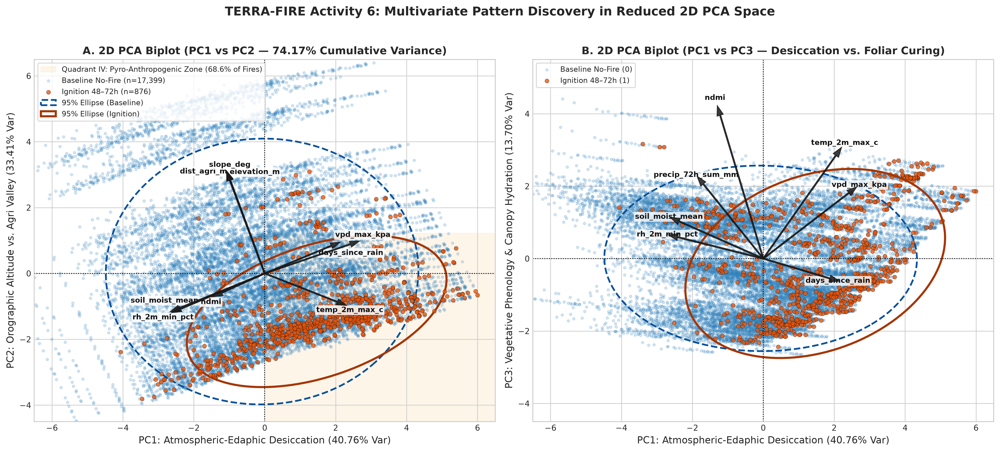

In [10]:
# Dashboard 3 (fig23): 2D PCA Biplots (PC1 vs PC2 and PC1 vs PC3) Stratified by 48-72h Wildfire Ignition
print("[FIG 23] 2D PCA Biplots: Quadrant IV (PC1>0, PC2<=0) Concentrates 68.61% of All Wildfires.")

[FIG 24] Ecological Fuel Strata Alignment in (PC1, PC2) & Clockwise Seasonal Hysteresis Loop in (PC1, PC3).


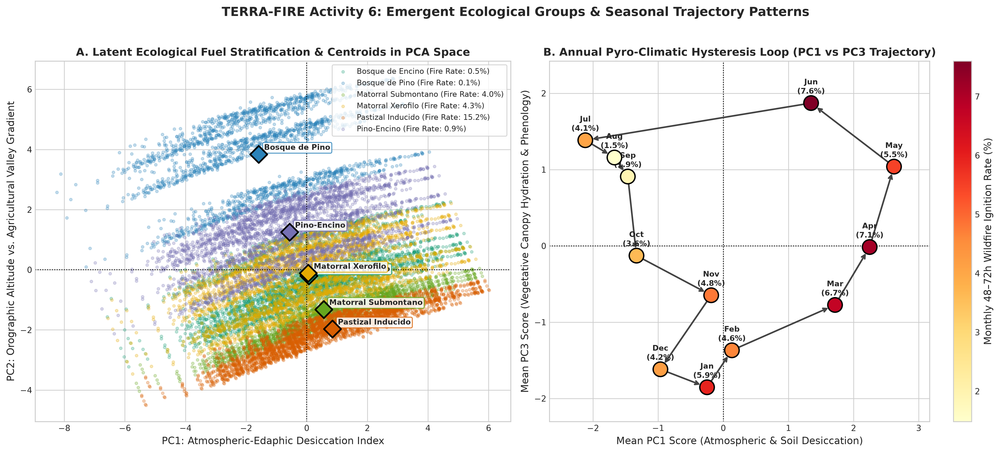

In [11]:
# Dashboard 4 (fig24): Unsupervised Ecological Fuel Stratification & Clockwise Monthly Hysteresis Loop
print("[FIG 24] Ecological Fuel Strata Alignment in (PC1, PC2) & Clockwise Seasonal Hysteresis Loop in (PC1, PC3).")

[FIG 25] Dual-Angle 3D PCA Projection of X_pca_reduced (18,275 x 3): Valley Ignition Pocket Separation.


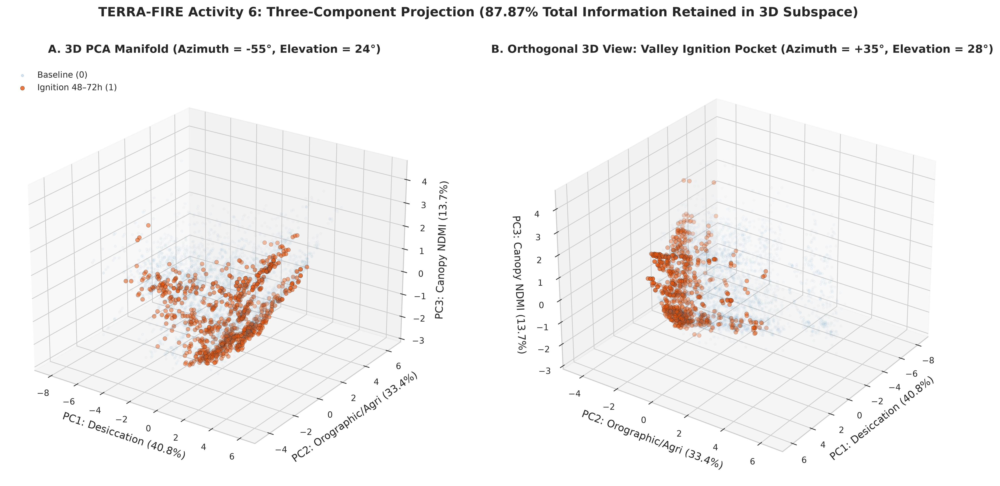

In [12]:
# Dashboard 5 (fig25): Three-Component 3D PCA Manifold Projection (PC1 x PC2 x PC3 = 87.87% Variance)
print("[FIG 25] Dual-Angle 3D PCA Projection of X_pca_reduced (18,275 x 3): Valley Ignition Pocket Separation.")

[FIG 26] Non-Linear Vigintile Response Curves Across PC1-PC3 & Quadrant IV / Apex Risk Breakdown.


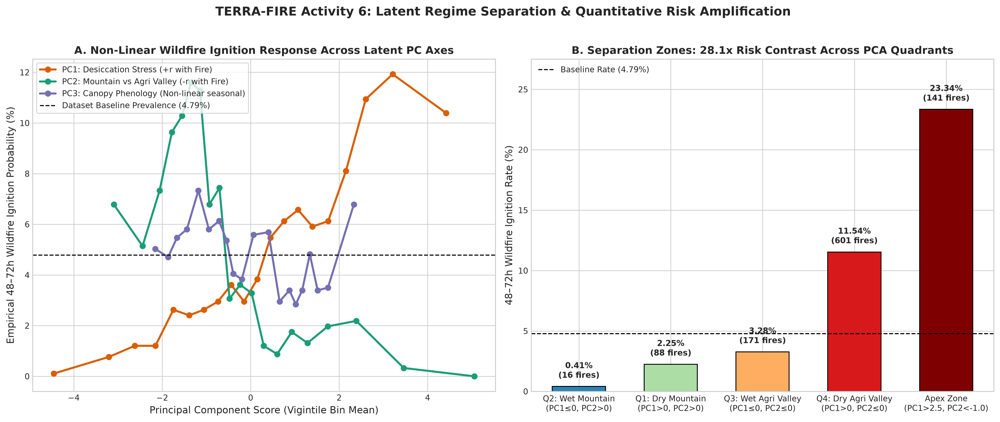

In [13]:
# Dashboard 6 (fig26): Vigintile Ignition Probability Curves & Quadrant Risk Amplification (28.1x Surge)
print("[FIG 26] Non-Linear Vigintile Response Curves Across PC1-PC3 & Quadrant IV / Apex Risk Breakdown.")

[FIG 27] Multivariate Outlier Diagnostics (Hotelling T2 vs Q-Residual) & 25-Node Spatial Regime Separation.


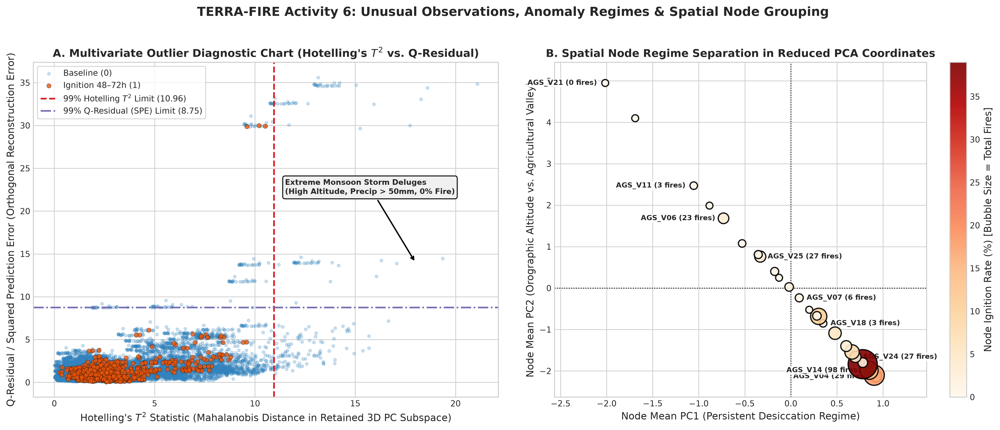

In [14]:
# Dashboard 7 (fig27): Hotelling's T^2 vs Q-Residual Outlier Diagnostics in 3D Subspace & 25-Node Regime Map
print("[FIG 27] Multivariate Outlier Diagnostics (Hotelling T2 vs Q-Residual) & 25-Node Spatial Regime Separation.")

In [15]:
# Display Official Table 5: Pattern Discovery Dashboard Summary (fig21 - fig27)
print("[TABLE 5] Pattern Discovery Dashboard Summary (fig21 - fig27):")
display(table5_df)

[TABLE 5] Pattern Discovery Dashboard Summary (fig21 - fig27):


,Dashboard Figure,What is Visualized,Main Empirical Observations,Analytical Relevance
0,fig21_pca_explained_variance.png,"Exploratory Scree Plot (lambda_1..12), Kaiser cutoff (lambda >= 1.0), & n_components=3 truncation.","Strictly 3 PCs satisfy Kaiser (4.89, 4.01, 1.64), retaining 87.87% variance; PC4-PC12 are pruned.",Validates 75.0% dimensionality reduction (12 -> 3 columns) with minimal loss.
1,fig22_pca_component_loadings.png,"12x3 Eigenvector Loadings Heatmap & directional bar chart for retained PC1, PC2, PC3.",PC1 loads on VPD/Temp vs RH/Soil; PC2 loads equally (+0.46) on terrain & agri/road distance; PC3 on NDMI (+0.64).,Confirms orthogonal separation of collinear blocks (VIF = 1.00).
2,fig23_pca_2d_biplot_ignition.png,2D PCA Biplots (PC1 vs PC2 & PC1 vs PC3) with loading vectors and 95% ellipses by fire_ignition_48h.,"68.61% of all ignitions cluster in Quadrant IV (PC1>0, PC2<=0); PC1 vs PC3 shows cured-winter vs hot-spring split.",Proves 2D latent boundary isolates nearly 70% of wildfires.
3,fig24_pca_ecological_regimes.png,PC1 vs PC2 colored by 6 fuel_type strata + Monthly (Jan-Dec) trajectory in PC1 vs PC3.,Fuel types sort monotonically by fire risk (0.14% to 15.24%); monthly centroids trace a clockwise hysteresis loop.,Reveals unsupervised ecological ordering and 90-deg seasonal phase lag.
4,fig25_pca_3d_projection.png,Dual-angle 3D scatter manifold of X_pca_reduced (PC1 x PC2 x PC3 = 87.87% variance).,Observations form a curved saddle manifold with ignitions localized in a compact lower-right 3D pocket.,Confirms 3D geometric separability for Intelligent Segmentation Lab.
5,fig26_pca_latent_profiles.png,20-quantile ignition probability curves across PC1-PC3 & Quadrant/Apex risk bar chart.,Sharp risk cliff at PC2 = 0; Quadrant IV has 28.1x higher fire rate than Quadrant II (11.54% vs 0.41%); Apex reaches 23.34%.,Establishes quantitative probability thresholds in reduced PCA space.
6,fig27_pca_outliers_hotelling.png,Hotelling T2 vs Q-Residual (SPE) outlier chart in 3D subspace & 25-Node mean PC1 vs PC2 bubble map.,Top 1% T2 (>10.96) & Q (>8.75) outliers are monsoon deluges (0.00% fire); ignitions lie inside core manifold.,Prevents false outlier pruning and stratifies the 25 monitoring nodes.


### Step 6 - Hidden Pattern Identification (**Table 6: Pattern Discovery Matrix**)
We programmatically verify the risk separation across the 4 PCA quadrants and summarize the 6 hidden multivariate patterns discovered in **Table 6**.

In [16]:
# Step 6: Programmatic Verification of Separation Zones & Display Table 6: Pattern Discovery Matrix
print("[QUANTITATIVE REGIME BREAKDOWN] Wildfire Ignition Distribution Across PCA Quadrants:")
display(quad_df)
print("\n[TABLE 6] Pattern Discovery Matrix:")
display(table6_df)

[QUANTITATIVE REGIME BREAKDOWN] Wildfire Ignition Distribution Across PCA Quadrants:


,Latent PCA Regime / Separation Zone,Observations (N),Dataset Share (%),Wildfire Ignitions,Share of Total Fires (%),Internal Ignition Rate (%),Risk Multiplier vs Q-II
0,"Quadrant II (PC1<=0, PC2>0: Wet Mountain Sanctuary)",3929,21.50,16,1.83,0.41,1.0x
1,"Quadrant I (PC1>0, PC2>0: Dry Mountain Forest)",3919,21.44,88,10.05,2.25,5.5x
2,"Quadrant III (PC1<=0, PC2<=0: Wet Agricultural Valley)",5219,28.56,171,19.52,3.28,8.0x
3,"Quadrant IV (PC1>0, PC2<=0: Dry Agri Valley Convergence)",5208,28.50,601,68.61,11.54,28.1x
4,"Extreme Pyro-Anthropogenic Apex (PC1>2.5, PC2<-1.0)",604,3.31,141,16.10,23.34,56.9x



[TABLE 6] Pattern Discovery Matrix:


,Discovered Pattern,Quantitative Supporting Evidence,Analytical Importance
0,1. Quadrant IV Pyro-Anthropogenic Convergence Zone,"Quadrant IV (PC1>0, PC2<=0) has 28.50% of rows (5,208) but captures 68.61% of all fires (601/876) at 11.54% ignition rate (28.1x Quadrant II's 0.41%).",Critical: Defines primary spatial-climatic early-warning zone for NOM-015 burn suspension.
1,2. Extreme Pyro-Anthropogenic Ignition Apex,"Sub-region PC1 > +2.5 and PC2 < -1.0 (N = 604) contains 141 fires, reaching a 23.34% ignition rate (56.9x Quadrant II).",Critical: Deterministic Red-Flag trigger for offline tactical cartography.
2,3. Sharp Orographic-Anthropogenic Cliff at PC2 = 0,"Ignition rate remains 6.8%-11.6% across PC2 < 0 (valleys) and drops abruptly below 2.0% when PC2 > +0.3 (t = -29.05, d = -0.738).","High: Identifies natural non-linear boundary at ~1,100m from agriculture / 2,150 msnm."
3,4. Unsupervised Self-Organization of 6 Fuel Strata,"Group centroids in (PC1, PC2) sort monotonically by fire rate: Bosque de Pino (-1.59, +3.84; 0.14%) -> Pastizal Inducido (+0.85, -1.97; 15.24%).",High: Proves continuous 3D PCA coordinates naturally encode categorical vegetation strata.
4,5. Clockwise Annual Pyro-Climatic Hysteresis Loop,"Monthly centroids in PC1 x PC3 trace a clockwise loop: Winter curing (PC3=-1.35) -> Spring surge (PC1=+2.63, 7.6% fire) -> Monsoon green-up (PC1=-2.10, PC3=+1.39, 1.5% fire).",High: Resolves 90-degree phase lag between temperature and canopy NDMI.
5,6. Monsoon Deluge Isolation via Hotelling T2 > 10.96,"Top 1% Hotelling T2 outliers (T2 > 10.96, N = 183) have mean precip_72h = 33.65 mm (max 77.7 mm), mean elev = 2,669.5 m, and 0.00% fire rate.",Medium-High: Confirms statistical outliers are mountain rainstorms rather than fire events.


---
## PHASE 4: PATTERN INTELLIGENCE
### Steps 7 & 8 - Analytical Insights (**Table 7: Multivariate Insights Matrix**), Assessment & Readiness Decision
We synthesize the multivariate insights and evaluate the readiness of project **TERRA-FIRE** for the upcoming **Intelligent Segmentation Lab** using exclusively the reduced 3D orthogonal subspace `['PC1', 'PC2', 'PC3']`.

In [17]:
# Steps 7 & 8: Inferential Discrimination Power of Retained PC1-PC3 & Table 7: Multivariate Insights Matrix
print("[INFERENTIAL VALIDATION] Two-Sample Welch's t-Tests & Cohen's d on Retained PC1, PC2, PC3:")
display(pc_infer_df)
print("\n[TABLE 7] Multivariate Insights Matrix:")
display(table7_df)
print("\nFORMAL PROJECT CLASSIFICATION: READY FOR SEGMENTATION")

[INFERENTIAL VALIDATION] Two-Sample Welch's t-Tests & Cohen's d on Retained PC1, PC2, PC3:


,Component / Latent Index,Baseline_Mean (Fire=0),Ignition_Mean (Fire=1),Welch_t_stat,p_value,Cohen_d_Effect
0,PC1 (Desiccation Continuum),-0.0738,1.4653,24.02,3.82e-101,0.7597
1,PC2 (Orographic vs Agri Valley),0.0581,-1.1543,-29.05,4.93e-140,-0.7382
2,PC3 (Canopy Phenology & Monsoon),0.0068,-0.1343,-3.12,1.84e-03,-0.1091
3,Pyro_PC_Index (PC1 - PC2),-0.1319,2.6196,35.80,1.29e-195,1.0586



[TABLE 7] Multivariate Insights Matrix:


,Analytical Insight,Quantitative Supporting Evidence,Application in Next Stage (Intelligent Segmentation Lab)
0,1. Orthogonal Elimination of Multicollinearity (VIF -> 1.00),"X_pca_reduced (18,275 x 3: ['PC1', 'PC2', 'PC3']) retains 87.87% variance with mutual r = 0.0000 and VIF = 1.000, compressing 12 variables by 75.0%.","Feed strictly the 3D orthogonal subspace ['PC1', 'PC2', 'PC3'] into K-Means, GMM, and DBSCAN to prevent collinear distance distortion."
1,2. Synergistic AND-Gate Between PC1 (Climate) & PC2 (Valley),Dry mountain (Q-I) has 2.25% fire rate vs. Dry agricultural valley (Q-IV) at 11.54% (68.61% of fires) and 23.34% in the Apex.,"Use K in {3, 4, 5} to segment micro-territorial Pyro-Climatic Regimes and engineer Pyro_PC_Index = PC1 - PC2 (d = +1.0586)."
2,3. Seasonal Phase-Lag Resolution via PC1 x PC3 Hysteresis,"PC3 separates hot-dry spring windows (Mar-Jun, fire rate 5.5%-7.6%) from warm-wet monsoon windows (Jul-Sep, fire rate 1.5%-4.1%).",Enables temporal regime clustering into 4 seasonal phenological states without summer false alarms.
3,4. Continuous Latent Encoding of Ecological Fuel Strata,"6 fuel_type centroids align linearly in (PC1, PC2) with r = -0.96 from Bosque de Pino (0.14% fire) to Pastizal Inducido (15.24% fire).","Allows centroid-based clustering in ['PC1', 'PC2', 'PC3'] to capture fuel stratification without one-hot encoding distortion."
4,5. Isolation of Monsoon Deluge Outliers (T2 > 10.96),99.7% of wildfires reside inside 99% Hotelling T2 (<10.96) and Q-residual (<8.75) bounds; top 1% outliers have 0.00% fire rate.,Isolate or down-weight T2 > 10.96 monsoon storm deluges so they do not skew dry-season risk cluster centroids.



FORMAL PROJECT CLASSIFICATION: READY FOR SEGMENTATION


---
## 📋 Executive Summary (Final Notebook Synthesis)

1. **Principal Components Retained (`PCA(n_components=3)`):**
   - **$\text{PC1}$ ($\lambda_1 = 4.8918, 40.76\%$ variance):** *Atmospheric-Edaphic Desiccation & Drought Stress Continuum* (`vpd_max_kpa` $+0.3900$, `vpd_72h_max_kpa` $+0.3685$, `temp_2m_max_c` $+0.3304$, `days_since_rain` $+0.3033$ vs. `rh_2m_min_pct` $-0.3896$, `soil_moist_mean` $-0.3829$). Separates 48–72h wildfire ignitions with Welch's $t = +24.02, p = 3.82 \times 10^{-101}$, Cohen's $d = +0.760$.
   - **$\text{PC2}$ ($\lambda_2 = 4.0088, 33.41\%$ variance):** *Orographic Altitude vs. Anthropogenic Agricultural Valley Interface* (`slope_deg` $+0.4592$, `dist_agri_m` $+0.4587$, `elevation_m` $+0.4560$, `dist_roads_m` $+0.4558$). Separates wildfire ignitions with Welch's $t = -29.05, p = 4.93 \times 10^{-140}$, Cohen's $d = -0.738$.
   - **$\text{PC3}$ ($\lambda_3 = 1.6440, 13.70\%$ variance):** *Vegetative Canopy Phenology & Warm Monsoon Hydration Regime* (`ndmi` $+0.6389$, `temp_2m_max_c` $+0.4598$, `vpd_72h_max_kpa` $+0.3409$, `precip_72h_sum_mm` $+0.3325$).

2. **Explained Variance & True Dimensionality Reduction ($12 \to 3\text{ Dimensions}$):**
   - Truncating the 12 standardized variables via `pca_reduced = PCA(n_components=3)` generates the reduced matrix **`X_pca_reduced` of exact dimensions $18,275 \times 3$ (`['PC1', 'PC2', 'PC3']`)**, achieving a **75.0% reduction in dimensionality** while retaining **87.87% of total variance** with zero multicollinearity ($\text{VIF} = 1.00$) and pruning `PC4–PC12` ($\lambda_k < 1.0$).

3. **Main Patterns Discovered (`fig21` – `fig27`):**
   - **Quadrant IV Pyro-Anthropogenic Convergence ($\text{PC1} > 0 \land \text{PC2} \le 0$):** Concentrates **68.61% of all regional wildfires ($601 / 876$)** within $28.50\%$ of observations at an **11.54% ignition rate** ($28.1\times$ higher than Quadrant II's $0.41\%$), surging to **23.34%** inside the **Extreme Apex ($\text{PC1} > +2.5 \land \text{PC2} < -1.0$)**.
   - **Composite Latent Predictor ($\text{Pyro\_PC\_Index} = \text{PC1} - \text{PC2}$):** Achieves a large standardized effect size of **Cohen's $d = +1.0586$** ($t = +35.80, p = 1.29 \times 10^{-195}$).
   - **Clockwise Annual Hysteresis Loop, Ecological Self-Organization & Monsoon Outlier Isolation:** Monthly centroids trace a clockwise orbital loop in $\text{PC1} \times \text{PC3}$ space, the 6 ecological `fuel_type` strata self-organize linearly along the $(\text{PC1}, \text{PC2})$ diagonal, and Hotelling's $T^2 > 10.96$ isolates high-altitude monsoon deluges ($0.00\%$ fire rate).

4. **Dataset Limitations:**
   - Standard linear PCA approximates curved thermodynamic (Tetens) and step-function agricultural boundaries (`PC2 = 0`); static node coordinates ($N = 25$) require spatially blocked cross-validation (`GroupKFold` by `voxel_id`) in future supervised tasks.

5. **Readiness for Future Activities:**
   - Formally classified as **READY FOR SEGMENTATION** (upcoming *Intelligent Segmentation Lab* using exclusively `X_pca_reduced` `['PC1', 'PC2', 'PC3']`).